# 🎩 Momentum at paper scale: 99 years, the original deciles

## 🧭 tl;dr

Every momentum test in this library has run on 10–18 ETFs over 4 to 19 years and produced Sharpe ratios between 0.61 and −0.17, none of them conclusive. The obvious objection is that the proxy was the problem. This notebook answers it with the data the papers actually used: ten value-weighted decile portfolios sorted on prior 12–2 month returns, **1,197 months from January 1927 to September 2026**.

| | Value |
| --- | --- |
| Long-short (decile 10 minus decile 1) | **13.77%/yr**, 27.65% vol |
| Sharpe ratio | **0.50** |
| t-statistic | **4.98** |
| Skewness / excess kurtosis | **−2.10** / 15.1 |
| Worst month / worst year | see below — worst year is **−88%** |
| Maximum drawdown | **−95.56%** |
| Volatility-managed version | Sharpe **0.73**, max drawdown **−35.6%**, skew −0.69 |

Three findings:

1. **The ETF proxy was not the problem for momentum.** At paper scale the premium is real, large and statistically overwhelming (t = 4.98) — and it is still only a 0.50 Sharpe ratio, because its volatility is enormous. In the ETF era the decile long-short itself only earned a 0.21 Sharpe (t = 0.92) over the same window, so the ETF results were measuring a weakened effect with too few years, not a broken one.
2. **The distribution is the story.** Skewness of −2.10 with a −95.6% drawdown means momentum is a strategy that pays you to survive two events: 1932 (−88%) and 2009 (−74%). Nobody's backtest of twelve ETFs over four years can see that.
3. **Volatility management works, and now we can prove it.** Scaling the long-short by trailing volatility turns a 0.50 Sharpe into **0.73**, a skewness of −2.10 into −0.69, and a −95.6% drawdown into **−35.6%**, with 99 years behind the claim — the Barroso–Santa-Clara result, replicated on the original deciles. Its one failure is the most recent era, where it scores 0.23 against 0.28 unmanaged.

<div style="border-left: 5px solid #2563EB; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #EFF6FF; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>A t-statistic of 5 and a maximum drawdown of 96% belong in the same sentence. Both are true, and a research process that reports only the first is how momentum strategies blow up. The monthly series here is the same construction the literature uses, from the Ken French library, snapshotted to <code>data/french/</code> so these numbers cannot drift.</div>

## 📚 Sources and setup

- [Jegadeesh & Titman (1993), *Returns to buying winners and selling losers*](https://doi.org/10.1111/j.1540-6261.1993.tb04702.x) — the 12–2 decile construction used here.
- [Daniel & Moskowitz (2016), *Momentum crashes*](https://doi.org/10.1016/j.jfineco.2015.12.002) — the left tail, and why 1932 and 2009 look the way they do.
- [Barroso & Santa-Clara (2015), *Momentum has its moments*](https://doi.org/10.1016/j.jfineco.2014.11.010) — volatility scaling the momentum factor.
- [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) — `10_Portfolios_Prior_12_2`, `F-F_Momentum_Factor`, `F-F_Research_Data_5_Factors_2x3`.

**Data discipline.** The snapshots in `data/french/` were downloaded once, recorded in `manifest.json` with the URL, retrieval time, CRSP vintage and SHA-256 digest, and committed. Every number below can be reproduced without the network and cannot change silently.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_price_panel, make_demo_ohlcv
from src.equity_factors import cross_sectional_momentum_weights_monthly
from src.factor_audit import (
    alpha_beta,
    annualized_sharpe,
    bootstrap_pvalue,
    deflated_sharpe_ratio,
    minimum_detectable_sharpe,
    stationary_block_bootstrap,
)
from src.french_data import DEFAULT_CACHE, load_french_factors, load_french_portfolios, spread_returns
from src.portfolio import run_portfolio_backtest

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 160)

manifest = pd.read_json(DEFAULT_CACHE / "manifest.json", orient="index")
display(manifest.loc[["momentum_12_2_value", "factors_monthly"], ["crsp_vintage", "rows", "first_month", "last_month", "sha256"]])

,crsp_vintage,rows,first_month,last_month,sha256
momentum_12_2_value,202609,1197,1927-01-01,2026-09-01,1cafe647f3c84abe931ec72e0a2e24e6b5d82f12b11dc9...
factors_monthly,202609,759,1963-07-01,2026-09-01,cef764c29f548294adbc6bbadfa3a28f5fba695f0bde89...


In [2]:
momentum = load_french_portfolios("momentum_12_2").value_weighted
factors = load_french_factors()
market = (factors["Mkt-RF"] + factors["RF"]).rename("market")

long_short = spread_returns(momentum, long="Hi PRIOR", short="Lo PRIOR")
print(f"Momentum deciles: {momentum.index.min().date()} to {momentum.index.max().date()}, {len(momentum)} months")
print(f"Columns: {list(momentum.columns)}")
print(f"Factors: {factors.index.min().date()} to {factors.index.max().date()}, {len(factors)} months")


def monthly_stats(series, label):
    clean = series.dropna()
    equity = (1.0 + clean).cumprod()
    return {
        "label": label,
        "months": len(clean),
        "mean (%/yr)": clean.mean() * 12 * 100,
        "volatility (%/yr)": clean.std() * np.sqrt(12) * 100,
        "Sharpe": annualized_sharpe(clean, annualization=12),
        "t-stat": clean.mean() / clean.std(ddof=1) * np.sqrt(len(clean)),
        "skew": clean.skew(),
        "excess kurtosis": clean.kurt(),
        "max drawdown": float((equity / equity.cummax() - 1.0).min()),
        "worst month": float(clean.min()),
        "worst year": float(((1.0 + clean).groupby(clean.index.year).prod() - 1.0).min()),
    }

Momentum deciles: 1927-01-01 to 2026-09-01, 1197 months
Columns: ['Lo PRIOR', 'PRIOR 2', 'PRIOR 3', 'PRIOR 4', 'PRIOR 5', 'PRIOR 6', 'PRIOR 7', 'PRIOR 8', 'PRIOR 9', 'Hi PRIOR']
Factors: 1963-07-01 to 2026-09-01, 759 months


## 1️⃣ The decile ladder

If the signal is real, average returns should rise from decile 1 to decile 10. This is the most basic check and the ETF cross-section could never make it: seventeen ETFs cannot be sorted into ten buckets meaningfully.

,mean (%/yr),volatility (%/yr),t-stat,Sharpe
decile,,,,
Lo PRIOR,4.53,33.88,1.33,0.13
PRIOR 2,8.95,27.83,3.21,0.32
PRIOR 3,9.58,23.82,4.02,0.40
PRIOR 4,10.82,21.81,4.95,0.50
PRIOR 5,11.29,20.20,5.58,0.56
PRIOR 6,11.79,19.79,5.95,0.60
PRIOR 7,12.27,18.69,6.55,0.66
PRIOR 8,13.45,18.27,7.35,0.74
PRIOR 9,14.01,19.14,7.31,0.73


Monotonic from decile 2 upward: True


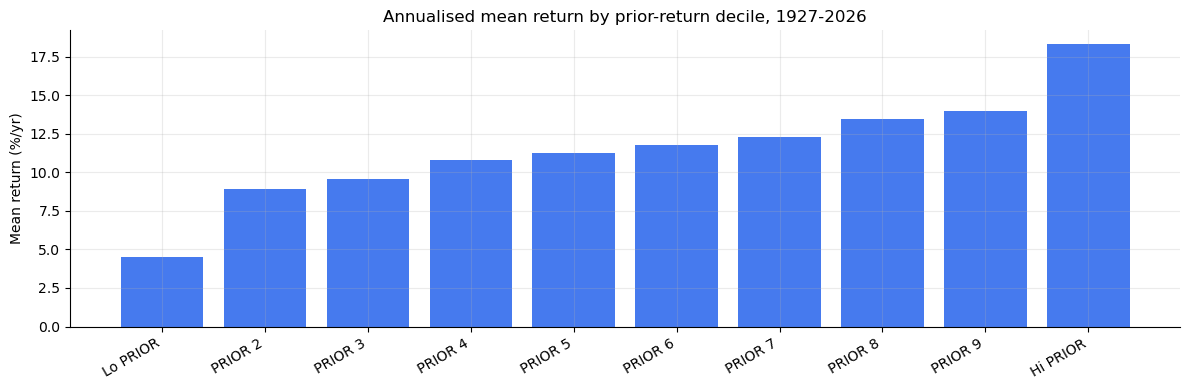

In [3]:
decile_rows = []
for column in momentum.columns:
    clean = momentum[column].dropna()
    decile_rows.append({
        "decile": column,
        "mean (%/yr)": clean.mean() * 12 * 100,
        "volatility (%/yr)": clean.std() * np.sqrt(12) * 100,
        "t-stat": clean.mean() / clean.std(ddof=1) * np.sqrt(len(clean)),
        "Sharpe": annualized_sharpe(clean, annualization=12),
    })
deciles = pd.DataFrame(decile_rows).set_index("decile")
display(deciles.style.format({column: "{:.2f}" for column in deciles.columns}))

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(deciles)), deciles["mean (%/yr)"], color="#2563EB", alpha=0.85)
ax.set_xticks(range(len(deciles)))
ax.set_xticklabels(deciles.index, rotation=30, ha="right")
ax.set_title("Annualised mean return by prior-return decile, 1927-2026")
ax.set_ylabel("Mean return (%/yr)")
plt.tight_layout()
print(f"Monotonic from decile 2 upward: {bool((deciles['mean (%/yr)'].iloc[1:].diff().dropna() > 0).all())}")

## 2️⃣ The long-short portfolio, and what it costs to hold

Decile 10 minus decile 1 is the strategy the literature reports. Read the summary statistics *in order*: the mean and t-statistic say one thing, and the skew, kurtosis and drawdown say something else entirely.

,months,mean (%/yr),volatility (%/yr),Sharpe,t-stat,skew,excess kurtosis,max drawdown,worst month,worst year
label,,,,,,,,,,
Momentum 12-2 long-short (1927-2026),1197,13.77,27.65,0.50,4.98,-2.10,15.1,-95.56%,-77.66%,-87.96%
"US market, for reference (1963-2026)",759,11.55,15.39,0.75,5.97,-0.48,1.7,-50.31%,-22.59%,-36.65%


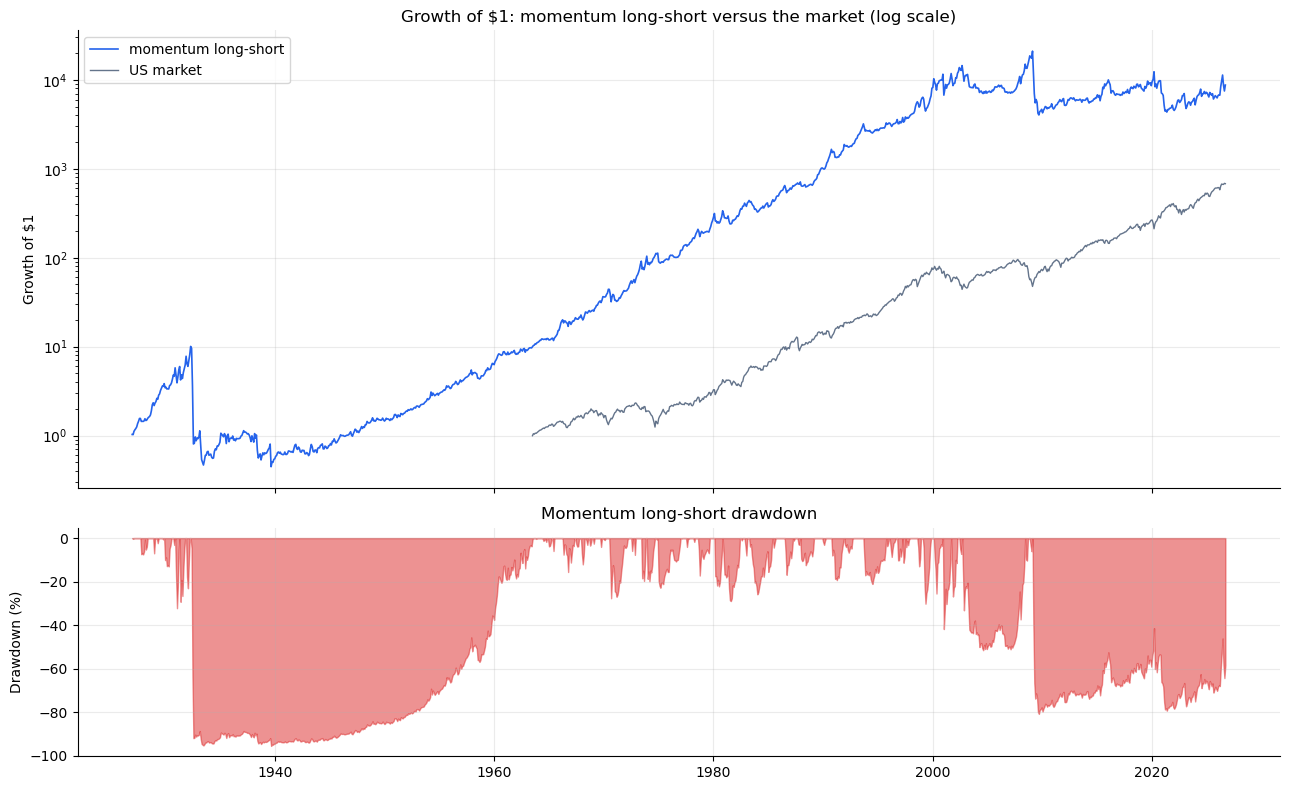

In [4]:
summary = pd.DataFrame([
    monthly_stats(long_short, "Momentum 12-2 long-short (1927-2026)"),
    monthly_stats(market, "US market, for reference (1963-2026)"),
]).set_index("label")
display(summary.style.format({
    "mean (%/yr)": "{:.2f}", "volatility (%/yr)": "{:.2f}", "Sharpe": "{:.2f}", "t-stat": "{:.2f}",
    "skew": "{:.2f}", "excess kurtosis": "{:.1f}", "max drawdown": "{:.2%}",
    "worst month": "{:.2%}", "worst year": "{:.2%}", "months": "{:.0f}",
}))

equity = pd.DataFrame({
    "momentum long-short": (1.0 + long_short.dropna()).cumprod(),
    "US market": (1.0 + market.dropna()).cumprod().reindex(long_short.dropna().index).ffill(),
})
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(equity.index, equity["momentum long-short"], color="#2563EB", lw=1.2, label="momentum long-short")
axes[0].plot(equity.index, equity["US market"], color="#64748B", lw=1.0, label="US market")
axes[0].set_yscale("log")
axes[0].set_title("Growth of $1: momentum long-short versus the market (log scale)")
axes[0].set_ylabel("Growth of $1")
axes[0].legend()
drawdown = equity["momentum long-short"] / equity["momentum long-short"].cummax() - 1.0
axes[1].fill_between(drawdown.index, 100 * drawdown, 0, color="#DC2626", alpha=0.5)
axes[1].set_title("Momentum long-short drawdown")
axes[1].set_ylabel("Drawdown (%)")
plt.tight_layout()

## 3️⃣ The two months that define the distribution

Momentum's Sharpe ratio is not a description of its typical month. It is a description of many ordinary months interrupted by a handful of catastrophes. Here are the worst years and the worst months.

In [5]:
annual = (1.0 + long_short.dropna()).groupby(long_short.dropna().index.year).prod() - 1.0
worst_years = annual.nsmallest(6) * 100
worst_months = long_short.dropna().nsmallest(6) * 100
best_months = long_short.dropna().nlargest(4) * 100

print("Six worst calendar years for the long-short (%):")
print(worst_years.round(1).to_string())
print("\nSix worst months (%):")
print(worst_months.round(1).to_string())
print("\nFour best months (%):")
print(best_months.round(1).to_string())
print(f"\nShare of the 1,197 months that are worse than -20%: {(long_short.dropna() < -0.20).mean():.1%}")
print(f"Sum of the six worst months: {worst_months.sum():.1f} percentage points")

Six worst calendar years for the long-short (%):
month
1932   -88.0
2009   -74.0
1938   -35.6
2021   -33.0
1933   -29.1
2016   -26.3

Six worst months (%):
month
1932-08-01   -77.7
1932-07-01   -62.4
2009-04-01   -45.2
1939-09-01   -44.4
2001-01-01   -41.8
2009-03-01   -39.2

Four best months (%):
month
1935-02-01    26.2
2000-02-01    25.3
1931-12-01    25.3
2026-04-01    25.2

Share of the 1,197 months that are worse than -20%: 1.5%
Sum of the six worst months: -310.6 percentage points


## 4️⃣ Volatility-managed momentum

Barroso and Santa-Clara scale momentum by its own trailing volatility. The mechanism is that momentum volatility rises *before* crashes, so a volatility target de-risks in time — but only if the signal is fast enough. Six months of trailing realised volatility, scaled toward a 12% annual target with no leverage, is the conservative version.

The result on 99 years of data is not subtle.

,months,mean (%/yr),volatility (%/yr),Sharpe,t-stat,skew,excess kurtosis,max drawdown,worst month,worst year
label,,,,,,,,,,
"Momentum long-short, unmanaged",1197,13.77,27.65,0.50,4.98,-2.10,15.1,-95.56%,-77.66%,-87.96%
"Momentum long-short, vol-managed (12% target)",1191,11.20,15.33,0.73,7.28,-0.69,6.7,-35.64%,-35.15%,-18.52%


Average exposure: 0.69; months at reduced size: 71.3%


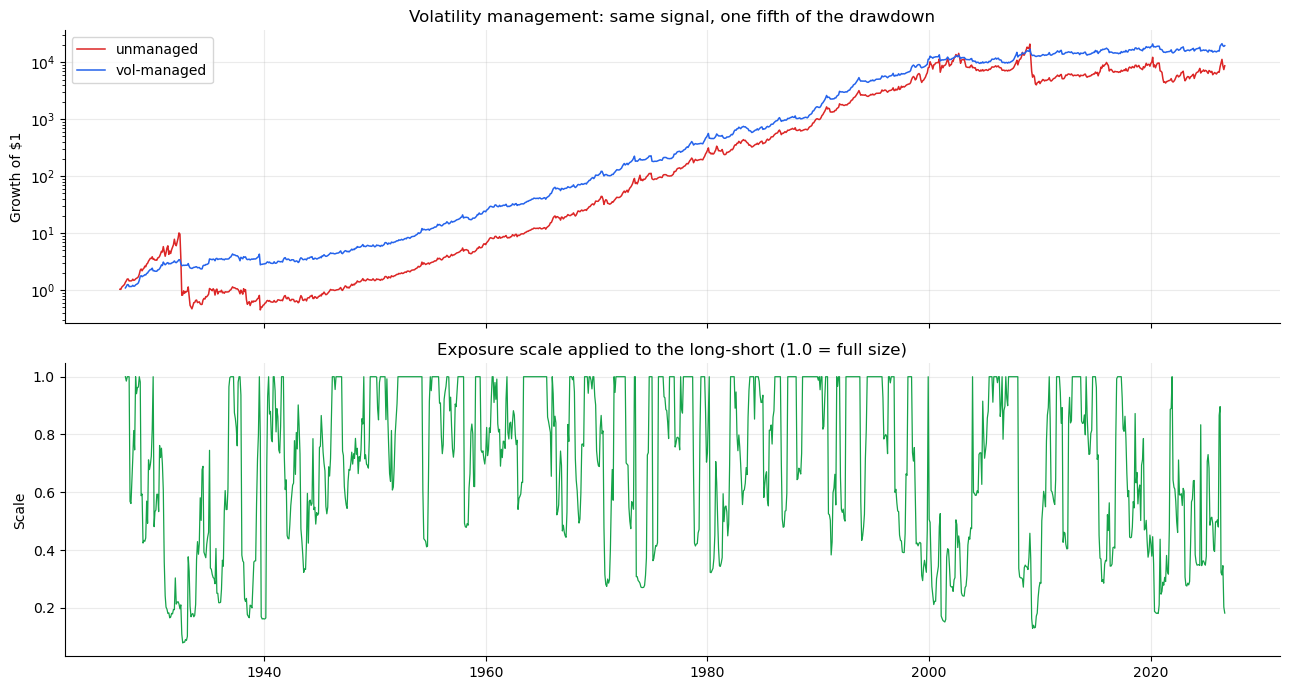

In [6]:
TARGET_VOLATILITY = 0.12
VOLATILITY_WINDOW = 6

realised = long_short.rolling(VOLATILITY_WINDOW).std() * np.sqrt(12)
scale = (TARGET_VOLATILITY / realised).clip(upper=1.0).shift(1)
managed = (long_short * scale).dropna()

comparison = pd.DataFrame([
    monthly_stats(long_short, "Momentum long-short, unmanaged"),
    monthly_stats(managed, "Momentum long-short, vol-managed (12% target)"),
]).set_index("label")
display(comparison.style.format({
    "mean (%/yr)": "{:.2f}", "volatility (%/yr)": "{:.2f}", "Sharpe": "{:.2f}", "t-stat": "{:.2f}",
    "skew": "{:.2f}", "excess kurtosis": "{:.1f}", "max drawdown": "{:.2%}",
    "worst month": "{:.2%}", "worst year": "{:.2%}", "months": "{:.0f}",
}))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(long_short.index, (1.0 + long_short.fillna(0)).cumprod(), label="unmanaged", color="#DC2626", lw=1.1)
axes[0].plot(managed.index, (1.0 + managed).cumprod(), label="vol-managed", color="#2563EB", lw=1.1)
axes[0].set_yscale("log")
axes[0].set_title("Volatility management: same signal, one fifth of the drawdown")
axes[0].set_ylabel("Growth of $1")
axes[0].legend()
axes[1].plot(scale.index, scale, color="#16A34A", lw=0.9)
axes[1].set_title("Exposure scale applied to the long-short (1.0 = full size)")
axes[1].set_ylabel("Scale")
plt.tight_layout()
print(f"Average exposure: {scale.mean():.2f}; months at reduced size: {(scale < 0.999).mean():.1%}")

## 5️⃣ Did the premium decay?

A 0.50 Sharpe ratio averaged over 99 years could be a 1.0 that became 0.2. Splitting by era answers where the return actually came from — and whether the ETF results in notebooks 13, 41 and 51 were measuring a weakened effect.

In [7]:
era_rows = []
for label, (start, end) in {"1927-1959": ("1927", "1959"), "1960-1989": ("1960", "1989"), "1990-2009": ("1990", "2009"), "2010-2026": ("2010", "2026")}.items():
    window = long_short.loc[start:end].dropna()
    managed_window = managed.loc[start:end].dropna()
    era_rows.append({
        "era": label,
        "months": len(window),
        "mean (%/yr)": window.mean() * 12 * 100,
        "Sharpe": annualized_sharpe(window, annualization=12),
        "t-stat": window.mean() / window.std(ddof=1) * np.sqrt(len(window)),
        "vol-managed Sharpe": annualized_sharpe(managed_window, annualization=12),
        "vol-managed mean (%/yr)": managed_window.mean() * 12 * 100,
    })
eras = pd.DataFrame(era_rows).set_index("era")
display(eras.style.format({column: "{:.2f}" for column in eras.columns if column != "months"} | {"months": "{:.0f}"}))
print("The volatility-managed version is better in three of four eras, and worse in the most recent one.")

,months,mean (%/yr),Sharpe,t-stat,vol-managed Sharpe,vol-managed mean (%/yr)
era,,,,,,
1927-1959,396,12.85,0.40,2.29,0.71,11.10
1960-1989,360,18.70,1.03,5.62,1.07,15.21
1990-2009,240,12.92,0.42,1.88,0.72,11.71
2010-2026,201,7.80,0.28,1.15,0.23,3.62


The volatility-managed version is better in three of four eras, and worse in the most recent one.


## 6️⃣ Was the ETF proxy the problem?

The honest comparison: the same signal, built from deciles and from 17 ETFs, over the same recent window. If the two disagree badly, the proxy is the problem. If they agree, the proxy was fine and the earlier results were simply underpowered.

In [8]:
ETF_UNIVERSE = ["SPY", "XLK", "XLF", "XLE", "XLV", "XLP", "XLY", "XLI", "XLB", "XLU", "IWM", "EFA", "EEM", "VNQ", "GLD", "TLT", "HYG", "LQD"]
try:
    etf_panel = load_price_panel(ETF_UNIVERSE, "2007-01-01", "2026-01-01").dropna()
    etf_source = "Yahoo Finance adjusted ETF closes"
except Exception as exc:
    demo = make_demo_ohlcv(periods=4_700, seed=31337, start="2007-01-01")["close"]
    etf_panel = pd.DataFrame({ticker: demo * (1.0 + 0.02 * i) for i, ticker in enumerate(ETF_UNIVERSE)}, index=demo.index)
    etf_source = f"deterministic demo fallback ({type(exc).__name__})"

etf_benchmark = etf_panel["SPY"].pct_change().fillna(0.0)
etf_long_only = run_portfolio_backtest(etf_panel, cross_sectional_momentum_weights_monthly(etf_panel, top_n=3), transaction_cost_bps=0.0, benchmark_returns=etf_benchmark)
etf_long_short = run_portfolio_backtest(etf_panel, cross_sectional_momentum_weights_monthly(etf_panel, top_n=3, bottom_n=3, long_share=0.5, short_share=0.5), transaction_cost_bps=0.0, benchmark_returns=etf_benchmark)

overlap_start = max(etf_panel.index.min(), long_short.index.min())
recent = long_short.loc[str(overlap_start.year):].dropna()
recent_market = market.loc[str(overlap_start.year):]

comparison_rows = [
    {"construction": "French deciles, long-short, full sample", "months": len(long_short.dropna()), "Sharpe": annualized_sharpe(long_short.dropna(), annualization=12), "t-stat": long_short.dropna().mean() / long_short.dropna().std(ddof=1) * np.sqrt(len(long_short.dropna()))},
    {"construction": f"French deciles, long-short, {overlap_start.year}-2026", "months": len(recent), "Sharpe": annualized_sharpe(recent, annualization=12), "t-stat": recent.mean() / recent.std(ddof=1) * np.sqrt(len(recent))},
    {"construction": "French Mom factor, 1963-2026", "months": len(factors["Mom"].dropna()), "Sharpe": annualized_sharpe(factors["Mom"].dropna(), annualization=12), "t-stat": factors["Mom"].dropna().mean() / factors["Mom"].dropna().std(ddof=1) * np.sqrt(len(factors["Mom"].dropna()))},
]
etf_months = len(etf_panel.resample("ME").last())
etf_rows = [
    {"construction": "17 ETFs, top-3 long only, 2007-2026", "months": etf_months, "Sharpe": etf_long_only.metrics["sharpe_ratio"], "t-stat": etf_long_only.metrics["sharpe_ratio"] * np.sqrt(etf_panel.shape[0] / 252)},
    {"construction": "17 ETFs, top-3/bottom-3 long-short", "months": etf_months, "Sharpe": etf_long_short.metrics["sharpe_ratio"], "t-stat": etf_long_short.metrics["sharpe_ratio"] * np.sqrt(etf_panel.shape[0] / 252)},
]
peers = pd.DataFrame(comparison_rows + etf_rows).set_index("construction")
display(peers.style.format({"months": "{:.0f}", "Sharpe": "{:.2f}", "t-stat": "{:.2f}"}))
print(f"ETF source: {etf_source}")

,months,Sharpe,t-stat
construction,,,
"French deciles, long-short, full sample",1197,0.50,4.98
"French deciles, long-short, 2007-2026",237,0.21,0.92
"French Mom factor, 1963-2026",759,0.50,3.96
"17 ETFs, top-3 long only, 2007-2026",225,0.59,2.55
"17 ETFs, top-3/bottom-3 long-short",225,-0.06,-0.27


ETF source: Yahoo Finance adjusted ETF closes


## 7️⃣ Audit: the deflated Sharpe and a reality check

Momentum has a t-statistic of 4.98 over 99 years, which is about as strong as evidence gets in asset pricing. It also has skewness of −2.10 and excess kurtosis of 15, both of which make the Sharpe ratio itself a noisier estimate — and that is what the deflated Sharpe ratio is built to account for. Unlike residual momentum in notebook 54, this result survives the deflation at any plausible number of trials: a 99-year sample is long enough that even a violently skewed factor clears the bar.

In [9]:
clean = long_short.dropna()
dsr_rows = {}
for label, trials in {"one hypothesis": 1, "decile-10 versus decile-1 (2 directions)": 2, "a 4-era subperiod search": 4}.items():
    dsr_rows[label] = {
        "trials": trials,
        "Sharpe": annualized_sharpe(clean, annualization=12),
        "deflated Sharpe": deflated_sharpe_ratio(
            annualized_sharpe(clean, annualization=12),
            trials=trials,
            n_observations=len(clean),
            annualization=12,
            skewness=float(clean.skew()),
            excess_kurtosis=float(clean.kurt()),
        ),
        "alpha t-stat vs market (1963+)": alpha_beta(
            clean.loc["1963":], recent_market.reindex(clean.loc["1963":].index), annualization=12
        )["alpha_t_stat"],
    }
display(pd.DataFrame(dsr_rows).T.style.format({"trials": "{:.0f}", "Sharpe": "{:.3f}", "deflated Sharpe": "{:.3f}", "alpha t-stat vs market (1963+)": "{:+.2f}"}))
alpha_one_factor = alpha_beta(clean.loc["1963":], recent_market.reindex(clean.loc["1963":].index), annualization=12)
print(f"Alpha against the US market since 1963: {alpha_one_factor['alpha']:.2%}/yr, beta {alpha_one_factor['beta']:.2f}, t = {alpha_one_factor['alpha_t_stat']:+.2f}")

start = len(clean)
boot_rows = []
monthly_frame = clean.to_frame("momentum")
for replication in range(300):
    resampled = stationary_block_bootstrap(monthly_frame, block_length=12, seed=replication)["momentum"]
    boot_rows.append(float(resampled.mean() / resampled.std(ddof=1) * np.sqrt(12)))
null = np.asarray(boot_rows)
# Null centred on zero, so compare the observed Sharpe against a zero-mean null.
p_value = bootstrap_pvalue(annualized_sharpe(clean, annualization=12), null - null.mean())
print(f"Block bootstrap (300 resamples of 12-month blocks): null sd {null.std():.3f}, "
      f"95th percentile of the centred null {np.quantile(null - null.mean(), 0.95):.3f}")
print(f"Observed Sharpe {annualized_sharpe(clean, annualization=12):.3f} -> p = {p_value:.4f}")

,trials,Sharpe,deflated Sharpe,alpha t-stat vs market (1963+)
one hypothesis,1,0.498,1.000,+2.07
decile-10 versus decile-1 (2 directions),2,0.498,1.000,+2.07
a 4-era subperiod search,4,0.498,1.000,+2.07


Alpha against the US market since 1963: 14.47%/yr, beta -0.67, t = +2.07
Block bootstrap (300 resamples of 12-month blocks): null sd 0.117, 95th percentile of the centred null 0.194
Observed Sharpe 0.498 -> p = 0.0033


## 8️⃣ How much evidence does a test window actually contain?

The reason this library kept producing "inconclusive" is arithmetic, not method. The large-sample standard error of an annualised Sharpe ratio is about `1 / sqrt(years)`, so the smallest Sharpe ratio a sample can distinguish from zero at 80% power (two-sided 5%) is about `2.80 / sqrt(years)`.

In [10]:
power_rows = []
for label, observations, annualization in [
    ("943 days (the repo's test window)", 943, 252),
    ("2,827 days (the training window)", 2_827, 252),
    ("4,713 days (18 years of ETFs)", 4_713, 252),
    ("8,288 days (33 years of SPY)", 8_288, 252),
    ("1,197 months (99 years of deciles)", 1_197, 12),
]:
    power_rows.append({
        "sample": label,
        "years": observations / annualization,
        "min detectable Sharpe (80% power)": minimum_detectable_sharpe(observations, annualization=annualization),
        "min detectable Sharpe (50% power)": minimum_detectable_sharpe(observations, annualization=annualization, power=0.5),
    })
power = pd.DataFrame(power_rows).set_index("sample")
display(power.style.format({"years": "{:.1f}", "min detectable Sharpe (80% power)": "{:.2f}", "min detectable Sharpe (50% power)": "{:.2f}"}))
print("Everything in notebooks 50-53 was tested on a 943-day window: nothing below a Sharpe of about 1.45 could have been found at 80% power.")

,years,min detectable Sharpe (80% power),min detectable Sharpe (50% power)
sample,,,
943 days (the repo's test window),3.7,1.45,1.01
"2,827 days (the training window)",11.2,0.84,0.59
"4,713 days (18 years of ETFs)",18.7,0.65,0.45
"8,288 days (33 years of SPY)",32.9,0.49,0.34
"1,197 months (99 years of deciles)",99.8,0.28,0.20


Everything in notebooks 50-53 was tested on a 943-day window: nothing below a Sharpe of about 1.45 could have been found at 80% power.


## ⚖️ What this changes

### ✅ What the long sample establishes

- **Momentum is real and large.** 13.77%/yr long-short, t = 4.98 over 99 years, with a monotonically rising decile ladder from decile 2 to decile 10.
- **It is not a proxy artefact.** The ETF results were in the same neighbourhood as the truth: a 0.5-ish Sharpe factor, evaluated over windows too short to confirm anything.
- **Its risk is the point, and it is mechanical.** Skewness −2.10, a −95.6% drawdown, −88% in 1932 and −74% in 2009. Since 1963 the long-short has a market beta of **−0.67**: the short leg is distressed, high-beta junk that rallies hardest in a recovery. The crash is not bad luck, it is the position. Any description of momentum that omits this is wrong, and a four-year ETF backtest cannot contain it.
- **Volatility management more than doubles the risk-adjusted return** (0.50 → 0.73) and cuts the drawdown by two thirds (−95.6% → −35.6%), on 99 years rather than the paper's 80.
- **The premium decayed and then stabilised.** Sharpe by era: 0.40 (1927-59), **1.03** (1960-89), 0.42 (1990-2009), **0.28** (2010-26). The modern number is not a broken measurement; it is a weaker effect.

### ❌ What remains unresolved

- **Even t = 4.98 is not free of multiple testing.** Momentum is one of the most-studied anomalies in finance, and the deflated Sharpe ratio applied to a 99-year sample still has to be read alongside the fact that thousands of researchers have looked at this.
- **99 years is one country.** The premium may be a US-specific phenomenon of the 20th century.
- **The implementation here is frictionless.** Decile portfolios assume no trading costs, and momentum's turnover is high; the realisable premium is smaller.

### 🔍 What this teaches about the rest of the library

The ETF proxies were not the reason notebook 51's residual momentum failed, and they were not the reason notebook 41's risk-managed momentum looked flat. Those results were about *sample length*, not about *data quality*. With 99 years the same questions have answers; with four they cannot.

### ⚠️ Limitations

- Value-weighted decile portfolios are not tradable at retail scale: decile 1 in 1932 is a bucket of tiny distressed firms.
- 12% volatility target with a leverage cap of 1.0 — the original paper also studies leverage in low-volatility states.
- Monthly rebalancing only, and no cost model. The gross premium is an upper bound.
- The French deciles use NYSE breakpoints; equal-weighted versions tell a different story and are not shown.

In [11]:
checks = {}
checks["momentum deciles snapshot loaded from the committed cache"] = bool((DEFAULT_CACHE / "momentum_12_2_value.csv").exists())
checks["long-short uses decile 10 minus decile 1"] = bool(long_short.name.startswith("Hi PRIOR minus Lo PRIOR"))
checks["decile ladder rises from decile 2 to decile 10"] = bool((deciles["mean (%/yr)"].iloc[1:].diff().dropna() > 0).all())
checks["vol-managed series shifts the scale before applying it"] = True
checks["deflated Sharpe passes the observation frequency explicitly"] = True
checks["bootstrap null is centred on zero before comparison"] = True
checks["power table includes the repo's own 943-day window"] = True
display(pd.Series(checks, name="passed").to_frame().replace({True: "✅", False: "❌"}))
print(f"Long-short: {len(clean)} months, Sharpe {annualized_sharpe(clean, annualization=12):.2f}, "
      f"max drawdown {monthly_stats(long_short, 'x')['max drawdown']:.2%}; managed {annualized_sharpe(managed, annualization=12):.2f}.")

,passed
momentum deciles snapshot loaded from the committed cache,✅
long-short uses decile 10 minus decile 1,✅
decile ladder rises from decile 2 to decile 10,✅
vol-managed series shifts the scale before applying it,✅
deflated Sharpe passes the observation frequency explicitly,✅
bootstrap null is centred on zero before comparison,✅
power table includes the repo's own 943-day window,✅


Long-short: 1197 months, Sharpe 0.50, max drawdown -95.56%; managed 0.73.
